<div style="padding: 30px; background-color: #f8f9fa; border-left: 6px solid #1a73e8; border-radius: 4px; margin-bottom: 24px;">
  <h1 style="color: #1a73e8; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; font-weight: 700; margin: 0 0 10px 0; font-size: 2.3rem;">Early Identification of Incorrect Customer Records Using Machine Learning</h1>
  <p style="color: #5f6368; font-family: 'Segoe UI', sans-serif; font-size: 1.1rem; margin: 0;"><b>Author:</b> Djahane Kleber Nzouatchep</p>
</div>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving idv_contact_data.db to idv_contact_data.db
Saving idv_merged_data.csv to idv_merged_data.csv
Saving idv_synthetic_data.csv to idv_synthetic_data.csv


In [ ]:
import pandas as pd
idv_df = pd.read_csv("idv_synthetic_data.csv")
idv_df.head()

,Customer_ID,Customer_Age,Recent_Mover,Time_since_verified,Suspected_geo_reloc,Recent_linked_joint,Failed_IDV
0,1,51,0,20,0,0,0
1,2,29,0,3,0,0,0
2,3,58,0,43,0,0,0
3,4,61,0,12,0,1,0
4,5,25,1,13,0,1,0


<div style="background-color: #e8f0fe; border: 1px solid #1a73e8; border-radius: 8px; padding: 22px; margin: 20px 0;">
<h3 style="color: #1a73e8; margin-top: 0; font-weight: 600;">✨ Executive Summary</h3>

<p style="line-height: 1.6;"><b>Accurate customer information</b> is essential for effective banking operations, regulatory compliance, and customer engagement. However, customer records can become outdated over time as individuals change address, telephone number, or other personal details. Inaccurate records may contribute to operational inefficiencies, failed identification and verification checks, poor customer experiences, and increased compliance risks. This study investigates whether machine learning techniques can assist in the early identification of customers whose records may require review and remediation.</p>

<p style="line-height: 1.6;">The analysis was conducted using two synthetic datasets comprising <b>5,000 customer observations</b>. The first dataset contained customer demographic and behavioural characteristics, including age, recent mover status, time since last verification, and indicators of potential geographic relocation. The second dataset contained measures of contact data quality, including returned mail and invalid telephone numbers. These datasets were merged to create a single analytical dataset for modelling purposes.</p>

<p style="line-height: 1.6;">Exploratory Data Analysis (EDA) was undertaken to understand the structure and characteristics of the data. Correlation analysis was then performed to investigate relationships between the predictor variables and <code>Failed_IDV</code>, the target variable indicating whether a customer failed an identification and verification check. Finally, a Logistic Regression model was developed and evaluated using a 70:30 training and testing split.</p>

<p style="line-height: 1.6;">The results suggest that indicators of customer relocation and contact-detail accuracy have the strongest association with failed identity verification outcomes. Suspected geographic relocation emerged as the most influential predictor, followed by recent mover status, returned mail, and incorrect telephone numbers. The Logistic Regression model achieved an overall accuracy of <b>92%</b>; however, its ability to identify failed identity verification cases was limited, largely reflecting the imbalance between successful and failed outcomes within the synthetic dataset.</p>

<p style="line-height: 1.6; margin-bottom: 0;">Although the analysis was conducted using synthetic data, the findings demonstrate how data-driven techniques can be applied to identify characteristics associated with customer record inaccuracies. Financial institutions may benefit from applying similar analytical approaches to real customer data to support data quality management, strengthen Know Your Customer (KYC) processes, and proactively address potential customer record issues.</p>
</div>

## 1. Introduction

Few services are as integral to modern life as banking, and the widespread adoption of online and mobile banking has made financial transactions more convenient than ever before. From a provider's perspective, maintaining accurate customer information is not only a regulatory requirement but also a fundamental component of effective risk management and marketing strategies.

However, customer details can become outdated over time as individuals change address, employment, income levels, telephone numbers, or other personal circumstances. This creates several risks for financial institutions, including increased fraud exposure, regulatory concerns, ineffective marketing campaigns, and poor customer experiences. For example, confidential correspondence may be sent to an incorrect address, while promotional offers may be directed towards customers who no longer meet the relevant eligibility criteria. Furthermore, many customer complaints arise when individuals are unable to pass identification and verification checks at the beginning of an interaction due to inaccurate information held on record.

This study investigates whether machine learning techniques can help a bank identify customers who are most likely to have inaccurate or outdated information on record. The objective is to determine whether these customers can be proactively identified and targeted for remedial action before such inaccuracies result in operational inefficiencies, compliance issues, customer dissatisfaction, or financial losses.

By developing a predictive framework, the study seeks to assess the feasibility of using data-driven approaches to improve data quality management and enhance customer engagement processes. There is no pretension here that the resulting model represents a definitive solution for predicting inaccurate customer records. Rather, the study aims to demonstrate a practical approach to supporting data accuracy and Know Your Customer (KYC) compliance through machine learning techniques.


##2. Background

Data mining for predictive and prescriptive analytics is a growing enterprise with applications across a wide range of industries. The Nebraska University Foundation, for example, leveraged Claritas, a data analytics platform, to identify prospective donors by developing a donor affinity model. The model was estimated to have the potential to generate approximately $800 million in donations from only 10% of prospective donors, demonstrating the value of segmentation and targeted marketing strategies.

Machine learning techniques have also been applied to financial distress prediction. A 2022 study by Jorge Zazueta Gutierrez, Andrea Chavez Heredia and Jorge Zazueta Hernández developed a bankruptcy prediction model using Support Vector Machine (SVM) techniques.¹ The study adopted a global perspective rather than focusing on a single country, drawing upon data from more than 450 companies across America, Asia and Europe. Such an approach potentially enhanced the robustness of the findings by reducing reliance upon a single economic or regulatory environment.

Machine learning has become sufficiently common that many of its applications are familiar to everyday users. Social media platforms such as Facebook use algorithms to suggest new connections based on shared networks, whilst banks routinely use predictive models when assessing credit applications. For example, applicants with higher educational attainment, stable employment, home ownership and higher incomes may be more likely to receive credit approval. Whilst human underwriters may review exceptional cases, predictive models frequently form the basis of the initial decision-making process.

In supervised learning, a machine learning model learns relationships within historical data and develops a mathematical function linking a target variable, or dependent variable, to a set of predictors, or independent variables.
Using the Cleveland Heart Disease Dataset, researchers have applied a variety of supervised learning techniques to predict the presence of heart disease, including Decision Trees, Naïve Bayes, Bagging Algorithms, Neural Network Ensembles and K-Nearest Neighbours.² These studies have generally reported high levels of predictive accuracy, demonstrating the effectiveness of machine learning for classification problems.

Classification, the supervised learning technique employed in this project, seeks to predict categorical outcomes. In binary classification, the target variable has two possible outcomes, such as approved or declined, fraud or non-fraud, customer retained or customer lost, or heart disease present or absent. Multiclass classification extends this principle to situations involving more than two categories. Common classification algorithms include Logistic Regression, Decision Trees, Naïve Bayes, K-Nearest Neighbours, Support Vector Machines and Neural Networks.

Among these techniques, Logistic Regression remains one of the most widely used classification methods. It estimates the probability that an observation belongs to a particular class and is especially suitable when the target variable has only two outcomes. Applications include credit approval, fraud detection, customer churn prediction, medical diagnosis and bankruptcy prediction. Its interpretability makes it particularly attractive within banking and other regulated industries, where understanding the factors influencing a prediction is often as important as the prediction itself.

The performance of classification models is commonly evaluated using unseen data and metrics such as accuracy, precision, recall, F1 score and the confusion matrix. Accuracy alone can be misleading when classes are imbalanced, as is often the case in fraud detection, bankruptcy prediction and other situations where the event of interest occurs relatively infrequently.

Not all machine learning problems involve a target variable. In unsupervised learning, algorithms seek patterns within unlabelled data. Clustering techniques such as K-Means are commonly used for customer segmentation and exploratory analysis. Whilst such methods can provide valuable insights into the structure of a dataset, they are not the primary focus of this study because the outcome of interest, identification and verification failure, is already known.

The examples discussed illustrate the breadth of machine learning applications across industries and problem domains. They also demonstrate the suitability of classification techniques for predicting binary outcomes. Because identification and verification failure can similarly be expressed as a binary outcome, machine learning provides a potentially valuable framework for identifying customer records that may require remediation before operational inefficiencies, compliance concerns or customer dissatisfaction arise.

Having established the suitability of machine learning techniques for binary classification problems, the next section describes the synthetic datasets used in this study and the assumptions underpinning their construction.


##3. Dataset Description
Given the practical constraints associated with obtaining real banking data, including governance approvals and data-access restrictions across multiple operational systems, this project uses synthetic data. Two synthetic datasets were generated and subsequently merged to create the final analytical dataset. The data-generation assumptions and business rules were reviewed through discussions with Know Your Customer (KYC) and customer operations professionals.


**Dataset 1: Customer Verification Data**

The first dataset, idv_synthetic_data.csv, contains 5,000 customer records and seven columns in total, comprising one identifier, one target variable and five predictor variables.
Customer_ID is a unique identifier and is excluded from the predictive model.
Failed_IDV is the target variable and indicates whether a fictional customer passes or fails an identification and verification check. The synthetic data was generated with an identification failure rate of approximately 8.6%.
The dataset contains the following predictor variables:
•	Customer_Age: Customer age in years, ranging from 18 to 98.
•	Time_since_verified: Number of months since the customer last completed identity verification with a bank representative.
•	Recent_Mover: Binary indicator reflecting whether the customer has been at their address for less than a year
•	Suspected_geo_reloc: Binary variable identifying whether transaction activity suggests a consistent geographic relocation pattern during the previous 90 days.
•	Recent_linked_joint: Binary indicator identifying whether the customer linked an externally held joint account during the previous 90 days.


**Dataset 2: Contact Data Quality Information**

The second dataset is stored within the SQL database idv_contact_data.db in a table named contact_data_quality. It contains 5,000 records and three variables.
•	Customer_ID: Unique customer identifier used to join the datasets.
•	Returned_Mail_Count_12m: Number of returned postal items during the previous 12 months.
•	Wrong_number_12m: Number of unsuccessful telephone contact attempts caused by invalid or incorrectly recorded telephone numbers during the previous 12 months.


**Merged Dataset**

The two datasets were merged into idv_merged_data.csv using Customer_ID as the primary key, resulting in a final dataset of 5,000 observations and nine variables, comprising seven predictors, one identifier and one target variable.


**Expected Predictor Effects**

Based on domain knowledge and the assumptions used during data generation, the following relationships are expected:
•	Longer Time_since_verified is expected to increase the probability of identification failure.
•	Customers with Recent_Mover = 1 are expected to exhibit a higher probability of identification failure
•	Higher Customer_age is expected to increase the probability of identification failure.
•	Suspected_geo_reloc = 1 is expected to increase the probability of identification failure and is anticipated to be the strongest predictor.
•	Recent_linked_joint = 1 is expected to have a moderate positive relationship with identification failure.
•	Higher values of Returned_Mail_Count_12m are expected to increase the probability of identification failure.
•	Higher values of Wrong_number_12m are expected to increase the probability of identification failure.

Overall, the merged dataset provides a suitable basis for exploratory data analysis and predictive modelling. The inclusion of demographic, behavioural, relocation and contact-quality indicators allows relationships with Failed_IDV to be investigated and provides an opportunity to assess whether machine learning techniques can identify characteristics associated with potentially inaccurate customer records.

### Dataset Summary Table

| Dataset | Records | Variables |
| :--- | :--- | :--- |
| Customer Verification Data | 5000 | 7 |
| Contact Quality Data | 5000 | 3 |
| Merged Dataset | 5000 | 9 |

## 4. Exploratory Data Analysis
Exploratory Data Analysis (EDA) was undertaken to understand the structure of the dataset, identify potential data quality issues and investigate relationships between the predictor variables and the target variable Failed_IDV. The analysis focuses on summary statistics, class balance, variable distributions and potential associations with identification verification failure.

In [ ]:
df.shape

(5000, 9)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Customer_ID              5000 non-null   int64
 1   Customer_Age             5000 non-null   int64
 2   Recent_Mover             5000 non-null   int64
 3   Time_since_verified      5000 non-null   int64
 4   Suspected_geo_reloc      5000 non-null   int64
 5   Recent_linked_joint      5000 non-null   int64
 6   Failed_IDV               5000 non-null   int64
 7   Returned_Mail_Count_12m  5000 non-null   int64
 8   Wrong_number_12m         5000 non-null   int64
dtypes: int64(9)
memory usage: 351.7 KB


In [ ]:
df.describe()

,Customer_ID,Customer_Age,Recent_Mover,Time_since_verified,Suspected_geo_reloc,Recent_linked_joint,Failed_IDV,Returned_Mail_Count_12m,Wrong_number_12m
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000
mean,2500.500000,47.170600,0.292000,18.167000,0.019200,0.106600,0.084000,0.056600,0.04760
std,1443.520003,14.529932,0.454728,15.172289,0.137241,0.308635,0.277416,0.236236,0.21294
min,1.000000,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,1250.750000,36.000000,0.000000,7.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,2500.500000,47.000000,0.000000,14.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,3750.250000,57.000000,1.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,5000.000000,98.000000,1.000000,120.000000,1.000000,1.000000,1.000000,2.000000,1.00000


In [ ]:
print(df.columns)

Index(['Customer_ID', 'Customer_Age', 'Recent_Mover', 'Time_since_verified',
       'Suspected_geo_reloc', 'Recent_linked_joint', 'Failed_IDV',
       'Returned_Mail_Count_12m', 'Wrong_number_12m'],
      dtype='object')


In [ ]:
df['Failed_IDV'].value_counts()

,count
Failed_IDV,
0,4580
1,420


##4.3 Descriptive Statistics
The merged dataset contains 5,000 observations and nine variables. Inspection of the dataset structure revealed that all variables contain 5,000 non-null values, indicating there are no missing observations. All variables are stored using an integer data type, reflecting either count, age or binary indicator variables.
The absence of missing values means data-cleaning procedures are not required before model development.

The average customer age is approximately 47 years, with ages ranging from 18 to 98 years. This suggests that the dataset represents a broad cross-section of adult customers.
Customers were last verified an average of 18 months prior to the observation date, although some records indicate periods of up to 120 months since verification. Such extended periods may increase the likelihood that customer information becomes outdated.
Approximately 29% of customers are classified as recent movers, whilst suspected geographic relocation patterns are observed in only around 2% of customers. These findings suggest that relocation-related indicators may be relatively uncommon but potentially important predictors of identification verification failure.




In [ ]:
df.groupby('Failed_IDV').mean()

,Customer_ID,Customer_Age,Recent_Mover,Time_since_verified,Suspected_geo_reloc,Recent_linked_joint,Returned_Mail_Count_12m,Wrong_number_12m
Failed_IDV,,,,,,,,
0,2491.692140,46.912009,0.272926,17.112664,0.014629,0.104367,0.051092,0.043668
1,2596.547619,49.990476,0.500000,29.664286,0.069048,0.130952,0.116667,0.090476


**4.4 Comparison of Customers Who Passed and Failed Identification Verification**

A comparison of mean predictor values between customers who passed and failed identification verification reveals several meaningful differences. Customers who failed identification verification were older on average, with a mean age of approximately 50 years compared with 47 years amongst customers who passed.

The most pronounced difference was observed for Time_since_verified. Customers who failed verification had not been verified for almost 30 months on average, compared with approximately 17 months for customers who successfully passed. This finding is consistent with the hypothesis that customer data becomes increasingly susceptible to inaccuracy as time elapses since the last verification event.

Half of customers who failed verification were classified as recent movers, compared with approximately 27% of customers who passed. Similarly, suspected geographic relocation patterns were observed considerably more frequently amongst customers who failed verification.

Measures of contact data quality displayed similar relationships. Both Returned_Mail_Count_12m and Wrong_number_12m were more than twice as high amongst customers who failed identification verification. This suggests that unsuccessful customer contact attempts may serve as useful indicators of potentially inaccurate customer records.

Overall, the results are broadly consistent with the assumptions used during data generation and provide preliminary evidence that the selected predictor variables contain useful information for identifying customers at increased risk of identification verification failure.



In [ ]:
df.groupby('Failed_IDV').mean().T

Failed_IDV,0,1
Customer_ID,2491.692140,2596.547619
Customer_Age,46.912009,49.990476
Recent_Mover,0.272926,0.500000
Time_since_verified,17.112664,29.664286
Suspected_geo_reloc,0.014629,0.069048
Recent_linked_joint,0.104367,0.130952
Returned_Mail_Count_12m,0.051092,0.116667
Wrong_number_12m,0.043668,0.090476


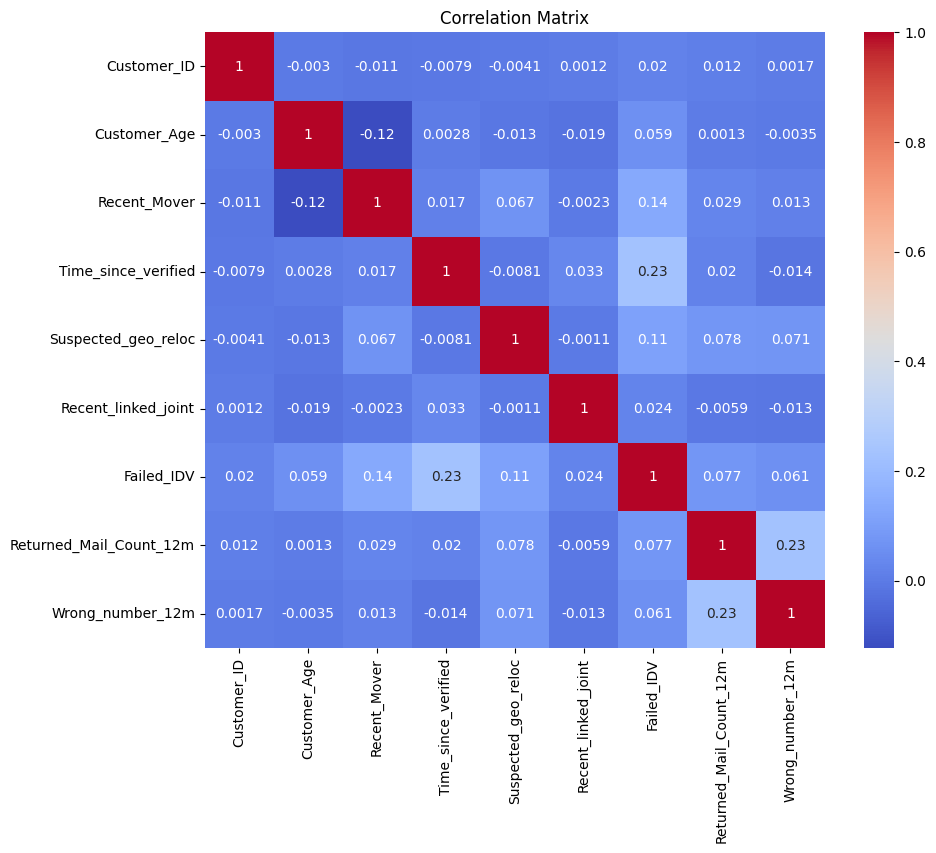

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

##4.5 Correlation Analysis


A correlation matrix above helps to examine the relationships between the predictor variables and the target variable, Failed_IDV. The strongest positive correlation with identification verification failure was observed for Time_since_verified (r = 0.23), suggesting that customers who have not recently completed verification activities are more likely to experience identification failures.

Recent_Mover (r = 0.14) and Suspected_geo_reloc (r = 0.11) also displayed positive associations with verification failure, providing further evidence that customer mobility may contribute to outdated records. Smaller positive relationships were observed for Customer_Age, Returned_Mail_Count_12m and Wrong_number_12m.

The correlation matrix also indicates relatively weak relationships between most predictor variables. This suggests that the variables capture distinct aspects of customer behaviour and data quality, reducing concerns regarding multicollinearity. Overall, the findings are consistent with the hypotheses established in the Dataset Description section and provide support for the development of a Logistic Regression model.


##5 Logistic Regression Model Development and Evaluation

This section develops and evaluates a Logistic Regression model to investigate the extent to which the selected predictor variables are associated with Failed_IDV. Following the exploratory data analysis and correlation analysis, logistic regression was applied to investigate the relationship between the predictor variables and Failed_IDV (the target variable indicating whether identity verification failed). Logistic regression was selected because it is well suited to binary classification problems. In addition to its predictive capability, logistic regression offers a high degree of interpretability, allowing the influence of individual predictors on the outcome to be examined. The predictor variables identified during the preceding analyses were subsequently used to develop the logistic regression model.

The dataset was divided into training and testing subsets, with 70% of observations allocated to model training and 30% reserved for model testing. This approach enabled the model to learn patterns from the training data while providing an independent dataset for model evaluation. The use of separate training and testing datasets helps reduce the risk of overfitting and provides a more reliable assessment of the model's ability to identify patterns in the data.

Logistic regression estimates the probability of an outcome occurring by modelling the relationship between the dependent variable and a set of independent variables. The resulting coefficients indicate the direction and relative strength of the relationship between each predictor and the likelihood of the outcome. Positive coefficient values indicate that an increase in the predictor is associated with a higher probability of the outcome occurring, whereas negative values suggest a decrease in this probability.

The logistic regression model was used primarily as an exploratory and illustrative tool to examine the relationships between predictor variables and the likelihood of customer record inaccuracies. Given that the analysis was conducted using synthetically generated data, the results should not be interpreted as evidence of real-world predictive performance. Instead, the findings demonstrate how financial institutions could apply similar analytical techniques to real customer datasets to identify factors associated with data quality issues and support improvements in customer record accuracy.


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Prepare features and target from the merged dataset (df)
# We drop 'Customer_ID' (identifier) and 'Failed_IDV' (target)
X = df.drop(columns=['Customer_ID', 'Failed_IDV'])
y = df['Failed_IDV']

# Split dataset (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

# Fit the Logistic Regression model
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)

# Predict
y_pred = log_reg.predict(X_test)


In [ ]:
# Generate and display classification report
print("Classification Report:\n")
print(classification_report(y_test, y_pred))


Classification Report:

              precision    recall  f1-score   support

           0       0.92      1.00      0.96      1374
           1       0.80      0.06      0.12       126

    accuracy                           0.92      1500
   macro avg       0.86      0.53      0.54      1500
weighted avg       0.91      0.92      0.89      1500



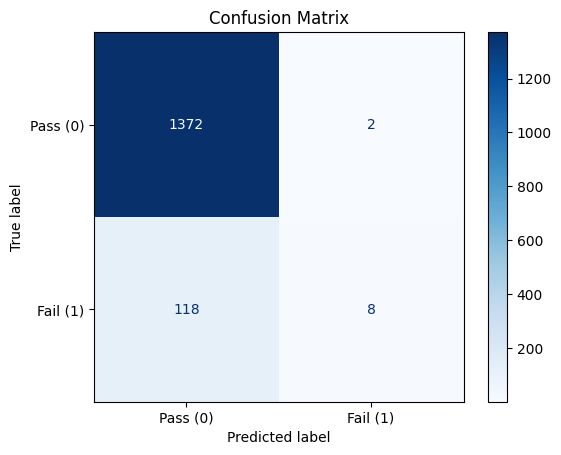

In [ ]:
# Generate and display Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Pass (0)', 'Fail (1)'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.show()


In [ ]:
# Generate and display Coefficients Table with all predictor variables
coefficients_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': log_reg.coef_[0]
})
coefficients_df['Odds_Ratio'] = np.exp(coefficients_df['Coefficient'])
coefficients_df = coefficients_df.sort_values(by='Coefficient', ascending=False).reset_index(drop=True)

print("Logistic Regression Coefficients:")
display(coefficients_df)


Logistic Regression Coefficients:


,Feature,Coefficient,Odds_Ratio
0,Suspected_geo_reloc,1.346731,3.844838
1,Recent_Mover,1.052294,2.864215
2,Returned_Mail_Count_12m,0.642194,1.900645
3,Wrong_number_12m,0.504119,1.655527
4,Recent_linked_joint,0.173840,1.189865
5,Time_since_verified,0.042523,1.043440
6,Customer_Age,0.019504,1.019695


The logistic regression model achieved an overall accuracy of 92% on the test dataset. The model demonstrated strong performance in identifying successful identity verification outcomes (Failed_IDV = 0). However, performance was weaker for failed identity verification outcomes (Failed_IDV = 1), with a recall score of 0.06 indicating that a relatively small proportion of failed cases were correctly detected. This outcome may reflect the imbalance between successful and failed verification records within the synthetic dataset.

The confusion matrix shows that the model correctly classified 1,372 successful identity verification outcomes and 8 failed identity verification outcomes. However, 118 failed cases were incorrectly classified as successful. These findings suggest that the model was considerably more effective at identifying successful identity verification outcomes than failed outcomes.

The logistic regression coefficients indicate that Suspected_geo_reloc and Recent_Mover were the strongest predictors of Failed_IDV. Returned_Mail_Count_12m and Wrong_number_12m also demonstrated meaningful positive relationships with failed identity verification outcomes. These findings suggest that customer relocation and inaccurate contact details may be important indicators of potential customer record inaccuracies.

<div style="background-color: #f1f8e9; border-left: 5px solid #7cb342; padding: 18px 20px; border-radius: 4px; margin: 20px 0;">
<h4 style="color: #33691e; margin-top: 0; font-weight: 600;">— Key Takeaway</h4>
<p style="margin: 0; line-height: 1.6; color: #2e7d32;">
  The logistic regression results suggest that indicators of customer relocation and contact-detail accuracy have the strongest association with failed identity verification outcomes. Suspected geographic relocation, recent mover status, returned mail, and incorrect telephone numbers emerged as the most influential predictors. By contrast, customer age and the time since a customer's details were last verified showed relatively weak relationships with <code>Failed_IDV</code>. <b>Banks seeking to improve customer record accuracy may benefit from focusing on customers whose circumstances indicate potential address or contact information changes.</b>
</p>
</div>

##6 Conclusion

This study investigated whether machine learning techniques could assist in the early identification of inaccurate customer records in a banking environment.
The logistic regression model achieved an overall accuracy of 92%; however, its ability to identify failed identity verification cases was limited. This outcome is likely influenced by the imbalance between successful and failed verification outcomes within the synthetic dataset. Consequently, the model should be viewed as an exploratory analytical tool rather than a production-ready predictive solution.

The findings demonstrate how data analytics techniques can be used to identify characteristics associated with customer record inaccuracies. Although the study was conducted using synthetic data, the approach provides a framework that financial institutions could apply to real customer datasets to better understand the drivers of identity verification failure.

Future research could incorporate real-world customer data, additional customer attributes and alternative machine learning techniques to further improve predictive performance. Financial institutions may benefit from prioritising customers who have recently relocated or whose contact information appears inaccurate, as these characteristics were found to be most strongly associated with failed identity verification outcomes in this study.


**References**

1.	Gutierrez, J.Z., Heredia, A.C. and Hernández, J.Z. (2022). Endogenous Prediction of Bankruptcy using a Support Vector Machinevector / International Journal of Combinatorial Optimization Problems and Informatics, 13(2), May-Aug 2022, 88–97. ISSN: 2007-1558

2.	Shouman, M., Turner, T. and Stocker, R. (2012). Applying K-Nearest Neighbour in Diagnosing Heart Disease Patients. International Journal of Information and Education Technology, Vol. 2, No. 3
